# Deep Data Analysis: Reverse Engineering LOB Features & Targets

## Objective
Exp_11b and exp_12 showed that t1 target remains challenging (~0.08 Pearson vs ~0.27 for t0).
This notebook investigates:
1. **Hidden patterns** in the raw data
2. **Reverse engineering** the organizers' transformations
3. **Normalization schemes** that might help
4. **Autoencoder** to denoise and extract signal
5. **Feature engineering** based on findings

The hypothesis: The key to improving t1 lies in understanding the underlying data transformations.

In [26]:
# Section 1: Import Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import pearsonr, spearmanr, kurtosis, skew
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, QuantileTransformer, PowerTransformer
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_regression
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import warnings
warnings.filterwarnings('ignore')

# Set style
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.6f}'.format)

print("Libraries loaded successfully!")

Libraries loaded successfully!


## Section 2: Load and Explore Raw Data

In [27]:
# Load data
train_df = pd.read_parquet('../datasets/train.parquet')
valid_df = pd.read_parquet('../datasets/valid.parquet')

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)
print(f"Train shape: {train_df.shape}")
print(f"Valid shape: {valid_df.shape}")
print(f"\nColumns: {train_df.columns.tolist()}")
print(f"\nData types:\n{train_df.dtypes}")
print(f"\nMissing values: {train_df.isnull().sum().sum()}")

# Separate feature groups
price_cols = [f'p{i}' for i in range(12)]
volume_cols = [f'v{i}' for i in range(12)]
dprice_cols = [f'dp{i}' for i in range(4)]
dvolume_cols = [f'dv{i}' for i in range(4)]
feature_cols = price_cols + volume_cols + dprice_cols + dvolume_cols
target_cols = ['t0', 't1']
meta_cols = ['seq_ix', 'step_in_seq', 'need_prediction']

print(f"\nFeature groups:")
print(f"  Price features (p0-p11): {len(price_cols)}")
print(f"  Volume features (v0-v11): {len(volume_cols)}")
print(f"  Delta price features (dp0-dp3): {len(dprice_cols)}")
print(f"  Delta volume features (dv0-dv3): {len(dvolume_cols)}")
print(f"  Total features: {len(feature_cols)}")

DATASET OVERVIEW
Train shape: (10721000, 37)
Valid shape: (1444000, 37)

Columns: ['seq_ix', 'step_in_seq', 'need_prediction', 'p0', 'p1', 'p2', 'p3', 'p4', 'p5', 'p6', 'p7', 'p8', 'p9', 'p10', 'p11', 'v0', 'v1', 'v2', 'v3', 'v4', 'v5', 'v6', 'v7', 'v8', 'v9', 'v10', 'v11', 'dp0', 'dp1', 'dp2', 'dp3', 'dv0', 'dv1', 'dv2', 'dv3', 't0', 't1']

Data types:
seq_ix               int64
step_in_seq          int64
need_prediction       int8
p0                 float64
p1                 float64
p2                 float64
p3                 float64
p4                 float64
p5                 float64
p6                 float64
p7                 float64
p8                 float64
p9                 float64
p10                float64
p11                float64
v0                 float64
v1                 float64
v2                 float64
v3                 float64
v4                 float64
v5                 float64
v6                 float64
v7                 float64
v8                 floa

In [3]:
# Basic statistics for all features
print("=" * 60)
print("FEATURE STATISTICS")
print("=" * 60)
print(train_df[feature_cols].describe())

FEATURE STATISTICS
                   p0              p1              p2              p3  \
count 10721000.000000 10721000.000000 10721000.000000 10721000.000000   
mean         1.406910       -1.210059        0.408193        0.851373   
std          0.460162        0.551705        0.156741        0.236283   
min          0.563016       -5.199338       -3.303641       -3.176243   
25%          1.025123       -1.525529        0.317650        0.727012   
50%          1.299272       -1.192071        0.373591        0.806365   
75%          1.597698       -0.832006        0.504922        0.884783   
max          5.199338        3.944545        5.199338        5.199338   

                   p4              p5              p6              p7  \
count 10721000.000000 10721000.000000 10721000.000000 10721000.000000   
mean        -0.125273       -0.277350        1.524261       -0.618656   
std          0.283449        0.243549        0.437707        0.292452   
min         -5.199338       -5.

## Section 3: Statistical Analysis of Target Variables

Let's deeply analyze t0 and t1 to understand why t1 is harder to predict.

In [4]:
# Target statistics
print("=" * 60)
print("TARGET VARIABLE ANALYSIS")
print("=" * 60)

# Only analyze where need_prediction == True
pred_df = train_df[train_df['need_prediction'] == True]
print(f"Samples with need_prediction=True: {len(pred_df):,}")

for target in ['t0', 't1']:
    data = pred_df[target].values
    print(f"\n--- {target} ---")
    print(f"  Mean: {np.mean(data):.6f}")
    print(f"  Std: {np.std(data):.6f}")
    print(f"  Min: {np.min(data):.6f}")
    print(f"  Max: {np.max(data):.6f}")
    print(f"  Median: {np.median(data):.6f}")
    print(f"  Skewness: {skew(data):.4f}")
    print(f"  Kurtosis: {kurtosis(data):.4f}")
    print(f"  % zeros: {(data == 0).mean() * 100:.2f}%")
    print(f"  % near-zero (|x| < 0.01): {(np.abs(data) < 0.01).mean() * 100:.2f}%")

# Correlation between t0 and t1
corr = pred_df['t0'].corr(pred_df['t1'])
print(f"\nCorrelation between t0 and t1: {corr:.4f}")

TARGET VARIABLE ANALYSIS
Samples with need_prediction=True: 9,659,621

--- t0 ---
  Mean: -0.166666
  Std: 0.842569
  Min: -34.393781
  Max: 41.651433
  Median: -0.239079
  Skewness: 2.2402
  Kurtosis: 23.4786
  % zeros: 0.00%
  % near-zero (|x| < 0.01): 0.00%

--- t1 ---
  Mean: -0.056591
  Std: 1.106947
  Min: -55.654362
  Max: 31.623109
  Median: -0.056446
  Skewness: -0.4830
  Kurtosis: 35.4729
  % zeros: 0.00%
  % near-zero (|x| < 0.01): 1.20%

Correlation between t0 and t1: 0.5053


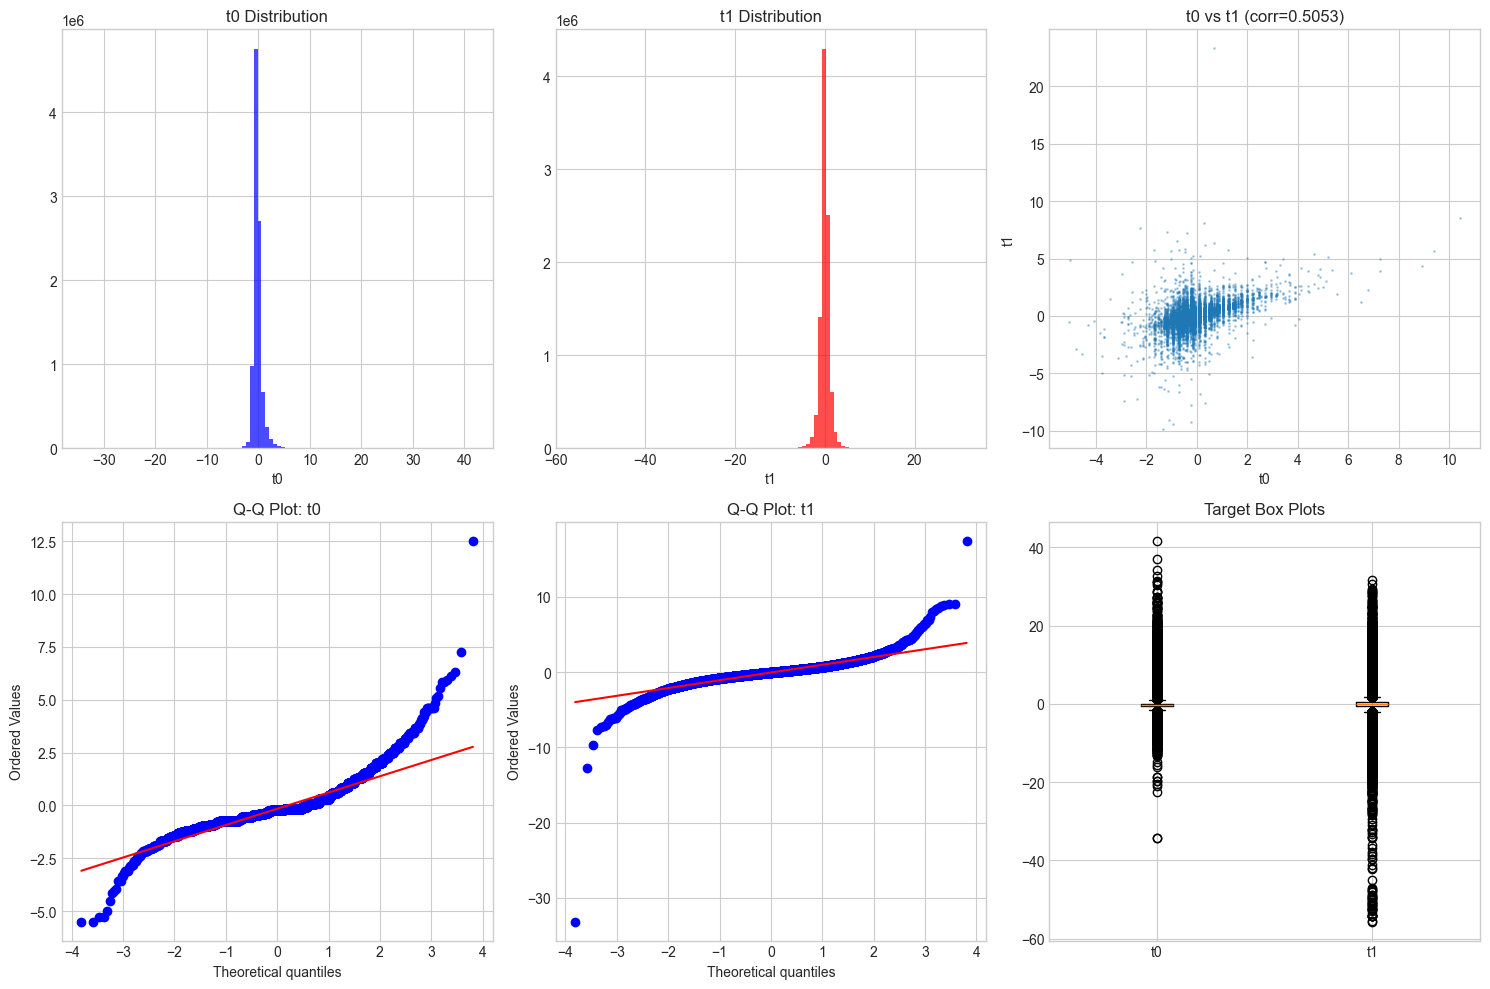

In [5]:
# Visualize target distributions
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# t0 distribution
axes[0, 0].hist(pred_df['t0'], bins=100, alpha=0.7, color='blue')
axes[0, 0].set_title('t0 Distribution')
axes[0, 0].set_xlabel('t0')

# t1 distribution  
axes[0, 1].hist(pred_df['t1'], bins=100, alpha=0.7, color='red')
axes[0, 1].set_title('t1 Distribution')
axes[0, 1].set_xlabel('t1')

# t0 vs t1 scatter
sample = pred_df.sample(min(10000, len(pred_df)))
axes[0, 2].scatter(sample['t0'], sample['t1'], alpha=0.3, s=1)
axes[0, 2].set_xlabel('t0')
axes[0, 2].set_ylabel('t1')
axes[0, 2].set_title(f't0 vs t1 (corr={corr:.4f})')

# Q-Q plots to check normality
stats.probplot(pred_df['t0'].sample(10000), dist="norm", plot=axes[1, 0])
axes[1, 0].set_title('Q-Q Plot: t0')

stats.probplot(pred_df['t1'].sample(10000), dist="norm", plot=axes[1, 1])
axes[1, 1].set_title('Q-Q Plot: t1')

# Box plots
axes[1, 2].boxplot([pred_df['t0'], pred_df['t1']], labels=['t0', 't1'])
axes[1, 2].set_title('Target Box Plots')

plt.tight_layout()
plt.show()

Computing target autocorrelations...


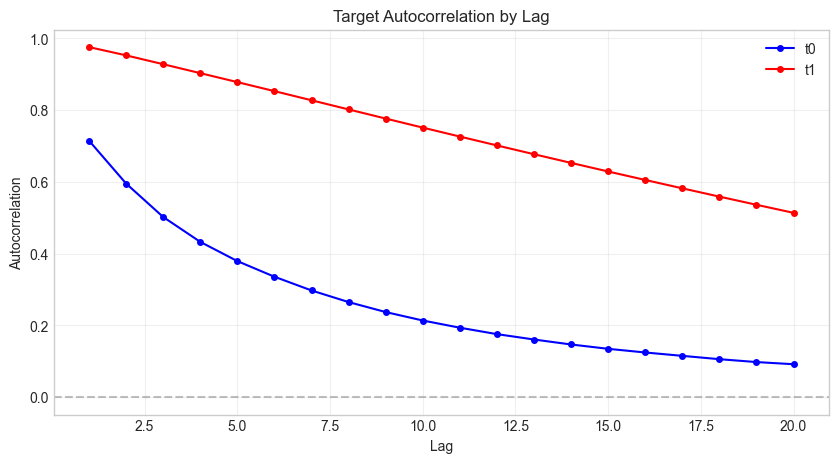


Key insight: t0 has stronger autocorrelation (easier to predict from history)
t0 lag-1 autocorr: 0.7149
t1 lag-1 autocorr: 0.9758


In [6]:
# Analyze autocorrelation of targets within sequences
# This helps understand if t1 is noisier or has different temporal structure

# Compute lagged correlations for targets
def compute_lag_correlations(df, col, max_lag=20):
    """Compute autocorrelation at different lags."""
    corrs = []
    for lag in range(1, max_lag + 1):
        df_lag = df.groupby('seq_ix')[col].shift(lag)
        corr = df[col].corr(df_lag)
        corrs.append(corr)
    return corrs

# Only use need_prediction samples
print("Computing target autocorrelations...")
t0_autocorr = compute_lag_correlations(train_df, 't0')
t1_autocorr = compute_lag_correlations(train_df, 't1')

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(range(1, 21), t0_autocorr, 'b-o', label='t0', markersize=4)
ax.plot(range(1, 21), t1_autocorr, 'r-o', label='t1', markersize=4)
ax.axhline(y=0, color='gray', linestyle='--', alpha=0.5)
ax.set_xlabel('Lag')
ax.set_ylabel('Autocorrelation')
ax.set_title('Target Autocorrelation by Lag')
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

print("\nKey insight: t0 has stronger autocorrelation (easier to predict from history)")
print(f"t0 lag-1 autocorr: {t0_autocorr[0]:.4f}")
print(f"t1 lag-1 autocorr: {t1_autocorr[0]:.4f}")

## Section 4: Feature Distribution Analysis

Analyze if features appear to be normalized/standardized and detect transformation patterns.

In [7]:
# Analyze feature statistics to detect normalization patterns
print("=" * 60)
print("FEATURE NORMALIZATION DETECTION")
print("=" * 60)

feature_stats = []
for col in feature_cols:
    data = train_df[col].values
    feature_stats.append({
        'feature': col,
        'mean': np.mean(data),
        'std': np.std(data),
        'min': np.min(data),
        'max': np.max(data),
        'skew': skew(data),
        'kurtosis': kurtosis(data),
        'is_centered': abs(np.mean(data)) < 0.1,
        'is_unit_std': abs(np.std(data) - 1) < 0.1,
    })

stats_df = pd.DataFrame(feature_stats)
print(stats_df.to_string(index=False))

print("\n--- Normalization Pattern Detection ---")
n_centered = stats_df['is_centered'].sum()
n_unit_std = stats_df['is_unit_std'].sum()
print(f"Features with mean ≈ 0: {n_centered}/{len(feature_cols)}")
print(f"Features with std ≈ 1: {n_unit_std}/{len(feature_cols)}")

FEATURE NORMALIZATION DETECTION
feature      mean      std       min       max      skew  kurtosis  is_centered  is_unit_std
     p0  1.406910 0.460162  0.563016  5.199338  1.216320  1.179283        False        False
     p1 -1.210059 0.551705 -5.199338  3.944545 -0.739031  0.538641        False        False
     p2  0.408193 0.156741 -3.303641  5.199338  1.710051 25.644874        False        False
     p3  0.851373 0.236283 -3.176243  5.199338  3.661825 19.524371        False        False
     p4 -0.125273 0.283449 -5.199338  5.199338 -3.369114 20.954135        False        False
     p5 -0.277350 0.243549 -5.199338  3.270130 -2.866021 19.657939        False        False
     p6  1.524261 0.437706  0.669996  5.199338  1.183496  1.308244        False        False
     p7 -0.618656 0.292452 -5.199338 -0.326746 -3.185801 13.382105        False        False
     p8  0.003883 0.192855 -3.977436  3.161358 -3.090659 25.350333         True        False
     p9 -1.219338 0.528716 -5.199338  

In [ ]:
# Visualize feature distributions - detect if uniform, normal, or other
fig, axes = plt.subplots(4, 8, figsize=(20, 12))
axes = axes.flatten()

for i, col in enumerate(feature_cols):
    if i < 32:
        sample_data = train_df[col].sample(min(50000, len(train_df)))
        axes[i].hist(sample_data, bins=50, alpha=0.7, density=True)
        axes[i].set_title(f'{col}', fontsize=9)
        axes[i].tick_params(labelsize=7)

plt.suptitle('Feature Distributions (all 32 features)', fontsize=14)
plt.tight_layout()
plt.show()

In [8]:
# Check for LOB structure: Are p0-p5 bid prices and p6-p11 ask prices?
# In a typical LOB: bid prices decrease (p0 > p1 > p2...) and ask prices increase (p6 < p7 < p8...)

# Sample one sequence to visualize
seq_sample = train_df[train_df['seq_ix'] == 0].head(100)

print("=" * 60)
print("LOB STRUCTURE ANALYSIS")
print("=" * 60)

# Check price ordering
print("\nPrice ordering check (first 100 steps of seq 0):")
print("Bid side (p0-p5) - should decrease:")
for i in range(5):
    col1, col2 = f'p{i}', f'p{i+1}'
    pct_ordered = (seq_sample[col1] >= seq_sample[col2]).mean() * 100
    print(f"  {col1} >= {col2}: {pct_ordered:.1f}%")

print("\nAsk side (p6-p11) - should increase:")
for i in range(6, 11):
    col1, col2 = f'p{i}', f'p{i+1}'
    pct_ordered = (seq_sample[col1] <= seq_sample[col2]).mean() * 100
    print(f"  {col1} <= {col2}: {pct_ordered:.1f}%")

# Check bid-ask spread
spread = seq_sample['p6'] - seq_sample['p0']
print(f"\nBid-Ask Spread (p6 - p0):")
print(f"  Mean: {spread.mean():.6f}")
print(f"  Min: {spread.min():.6f}")
print(f"  All positive: {(spread > 0).all()}")

LOB STRUCTURE ANALYSIS

Price ordering check (first 100 steps of seq 0):
Bid side (p0-p5) - should decrease:
  p0 >= p1: 100.0%
  p1 >= p2: 0.0%
  p2 >= p3: 0.0%
  p3 >= p4: 100.0%
  p4 >= p5: 88.0%

Ask side (p6-p11) - should increase:
  p6 <= p7: 0.0%
  p7 <= p8: 100.0%
  p8 <= p9: 0.0%
  p9 <= p10: 100.0%
  p10 <= p11: 1.0%

Bid-Ask Spread (p6 - p0):
  Mean: 0.066061
  Min: -1.185021
  All positive: False


## Section 5: Correlation and Dependency Analysis

In [9]:
# Compute correlations: Features vs Targets
print("=" * 60)
print("FEATURE-TARGET CORRELATIONS")
print("=" * 60)

# Use only need_prediction samples for target correlations
pred_mask = train_df['need_prediction'] == True
pred_data = train_df[pred_mask]

# Pearson correlations
corr_t0 = pred_data[feature_cols].corrwith(pred_data['t0'])
corr_t1 = pred_data[feature_cols].corrwith(pred_data['t1'])

# Spearman correlations (captures non-linear monotonic relationships)
spearman_t0 = pred_data[feature_cols].apply(lambda x: x.corr(pred_data['t0'], method='spearman'))
spearman_t1 = pred_data[feature_cols].apply(lambda x: x.corr(pred_data['t1'], method='spearman'))

corr_df = pd.DataFrame({
    'feature': feature_cols,
    'pearson_t0': corr_t0.values,
    'pearson_t1': corr_t1.values,
    'spearman_t0': spearman_t0.values,
    'spearman_t1': spearman_t1.values,
})

print("\nTop 10 correlations with t0:")
print(corr_df.sort_values('pearson_t0', key=abs, ascending=False).head(10).to_string(index=False))

print("\nTop 10 correlations with t1:")
print(corr_df.sort_values('pearson_t1', key=abs, ascending=False).head(10).to_string(index=False))

FEATURE-TARGET CORRELATIONS

Top 10 correlations with t0:
feature  pearson_t0  pearson_t1  spearman_t0  spearman_t1
     p0   -0.135584   -0.015024    -0.176753    -0.013430
     p2   -0.105429   -0.012250    -0.120944    -0.000835
     p8    0.102229   -0.004644     0.141888     0.006020
     v8    0.097171    0.035607     0.124377     0.045005
     p1    0.070197    0.006404     0.108480     0.015251
     v2   -0.069031   -0.026600    -0.086148    -0.032076
    dv3    0.066771    0.029669     0.075134     0.025821
    dv2    0.063890    0.025256     0.057862     0.019703
     p4    0.063631    0.012335     0.067800     0.018073
     p3   -0.062639   -0.018350    -0.073297    -0.010370

Top 10 correlations with t1:
feature  pearson_t0  pearson_t1  spearman_t0  spearman_t1
     v8    0.097171    0.035607     0.124377     0.045005
     v0   -0.051646   -0.030486    -0.058831    -0.031852
     v1    0.061491    0.030274     0.075074     0.036588
    dv3    0.066771    0.029669     0.0751

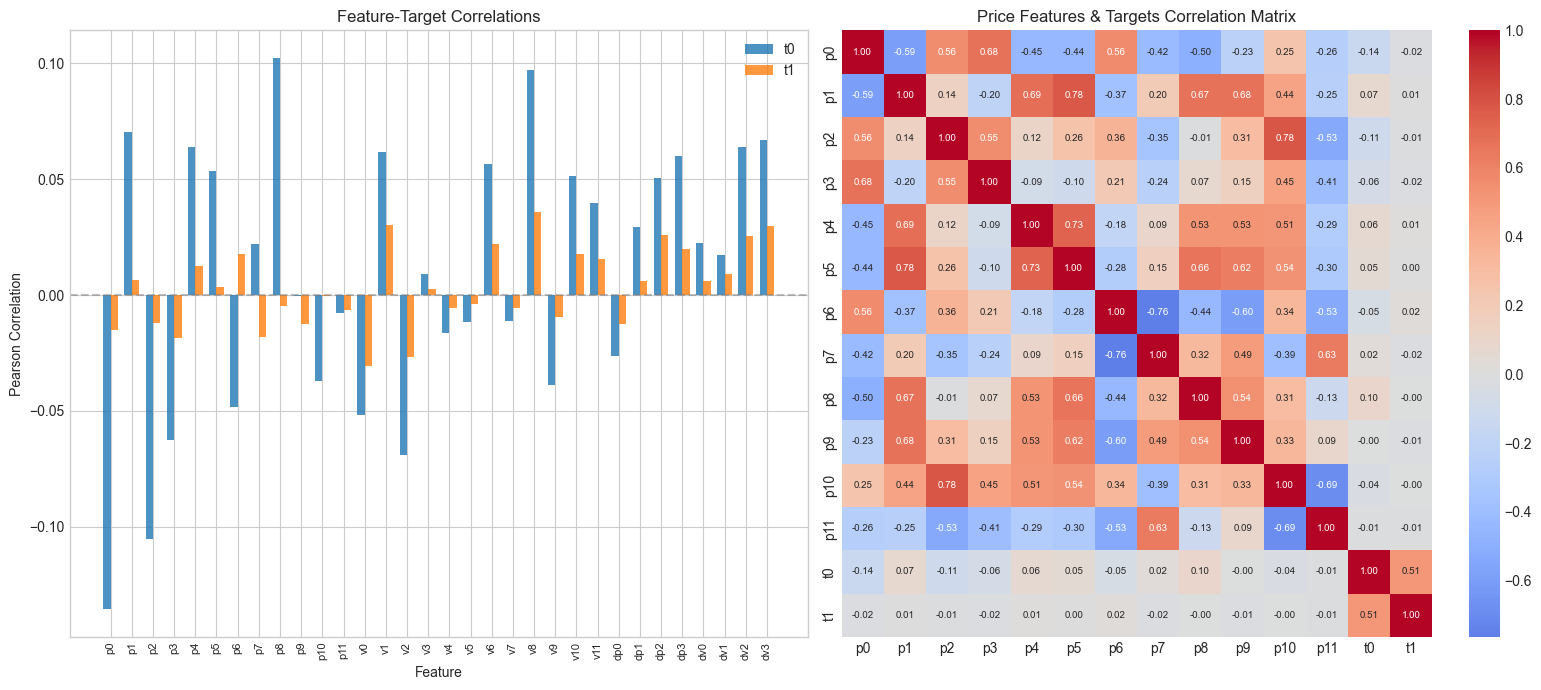

In [10]:
# Full correlation heatmap
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Feature-target correlations bar chart
x = np.arange(len(feature_cols))
width = 0.35

axes[0].bar(x - width/2, corr_t0.values, width, label='t0', alpha=0.8)
axes[0].bar(x + width/2, corr_t1.values, width, label='t1', alpha=0.8)
axes[0].set_xlabel('Feature')
axes[0].set_ylabel('Pearson Correlation')
axes[0].set_title('Feature-Target Correlations')
axes[0].set_xticks(x)
axes[0].set_xticklabels(feature_cols, rotation=90, fontsize=8)
axes[0].legend()
axes[0].axhline(y=0, color='gray', linestyle='--', alpha=0.5)

# Feature-feature correlation matrix (subset)
feature_subset = price_cols[:6] + price_cols[6:12] + ['t0', 't1']
corr_matrix = pred_data[feature_subset].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, 
            ax=axes[1], annot_kws={'size': 7})
axes[1].set_title('Price Features & Targets Correlation Matrix')

plt.tight_layout()
plt.show()

In [11]:
# Mutual Information - captures non-linear dependencies
print("=" * 60)
print("MUTUAL INFORMATION (Non-linear dependencies)")
print("=" * 60)

# Sample for computational efficiency
sample_size = 50000
sample_idx = np.random.choice(len(pred_data), size=min(sample_size, len(pred_data)), replace=False)
X_sample = pred_data.iloc[sample_idx][feature_cols].values
y_t0_sample = pred_data.iloc[sample_idx]['t0'].values
y_t1_sample = pred_data.iloc[sample_idx]['t1'].values

print("Computing mutual information (this may take a moment)...")
mi_t0 = mutual_info_regression(X_sample, y_t0_sample, random_state=42)
mi_t1 = mutual_info_regression(X_sample, y_t1_sample, random_state=42)

mi_df = pd.DataFrame({
    'feature': feature_cols,
    'MI_t0': mi_t0,
    'MI_t1': mi_t1,
})

print("\nTop 10 Mutual Information with t0:")
print(mi_df.sort_values('MI_t0', ascending=False).head(10).to_string(index=False))

print("\nTop 10 Mutual Information with t1:")
print(mi_df.sort_values('MI_t1', ascending=False).head(10).to_string(index=False))

print(f"\nTotal MI ratio (t0/t1): {mi_df['MI_t0'].sum() / mi_df['MI_t1'].sum():.2f}")
print("Higher ratio indicates t0 has more predictable signal in features")

MUTUAL INFORMATION (Non-linear dependencies)
Computing mutual information (this may take a moment)...

Top 10 Mutual Information with t0:
feature    MI_t0    MI_t1
     p7 0.901292 0.094315
     p2 0.842481 0.094395
     p3 0.836820 0.090684
     p8 0.822825 0.095873
     p5 0.812719 0.100383
     p4 0.811522 0.094323
    p11 0.811147 0.096976
     p0 0.809350 0.093993
     p9 0.803515 0.096972
    p10 0.797777 0.102444

Top 10 Mutual Information with t1:
feature    MI_t0    MI_t1
    dv3 0.445607 0.134469
    dv2 0.473971 0.132058
    dv1 0.448493 0.130633
    dv0 0.436845 0.123690
    p10 0.797777 0.102444
     p5 0.812719 0.100383
     p6 0.791656 0.098319
    p11 0.811147 0.096976
     p9 0.803515 0.096972
     p8 0.822825 0.095873

Total MI ratio (t0/t1): 7.53
Higher ratio indicates t0 has more predictable signal in features


## Section 6: Reverse Engineering Feature Transformations

Try to understand if features were transformed (log, sqrt, standardized per-sequence, etc.)

In [12]:
# Hypothesis 1: Features might be standardized per-sequence
# Check if each sequence has mean~0 and std~1 for each feature

print("=" * 60)
print("PER-SEQUENCE NORMALIZATION CHECK")
print("=" * 60)

# Sample sequences
seq_ids = train_df['seq_ix'].unique()[:100]

per_seq_stats = []
for col in feature_cols[:8]:  # Check first 8 features
    seq_means = train_df.groupby('seq_ix')[col].mean()
    seq_stds = train_df.groupby('seq_ix')[col].std()
    per_seq_stats.append({
        'feature': col,
        'mean_of_seq_means': seq_means.mean(),
        'std_of_seq_means': seq_means.std(),
        'mean_of_seq_stds': seq_stds.mean(),
        'std_of_seq_stds': seq_stds.std(),
    })

per_seq_df = pd.DataFrame(per_seq_stats)
print("Per-sequence statistics:")
print(per_seq_df.to_string(index=False))

print("\nIf data was z-normalized per sequence:")
print("  - mean_of_seq_means should be ~0")
print("  - mean_of_seq_stds should be ~1")

PER-SEQUENCE NORMALIZATION CHECK
Per-sequence statistics:
feature  mean_of_seq_means  std_of_seq_means  mean_of_seq_stds  std_of_seq_stds
     p0           1.406910          0.232504          0.380422         0.114605
     p1          -1.210059          0.206565          0.492746         0.138486
     p2           0.408193          0.042355          0.140893         0.054280
     p3           0.851373          0.100511          0.178732         0.117601
     p4          -0.125273          0.064830          0.248907         0.119430
     p5          -0.277350          0.066865          0.209677         0.104580
     p6           1.524261          0.213817          0.366333         0.108723
     p7          -0.618656          0.134903          0.221442         0.135513

If data was z-normalized per sequence:
  - mean_of_seq_means should be ~0
  - mean_of_seq_stds should be ~1


LOG TRANSFORMATION CHECK
If prices are log-transformed, exp(p) should be positive and show price-like behavior

Original p0 range: 0.9377387694593856 to 2.969020480242811
exp(p0) range: 2.554199250034274 to 19.472836223477298


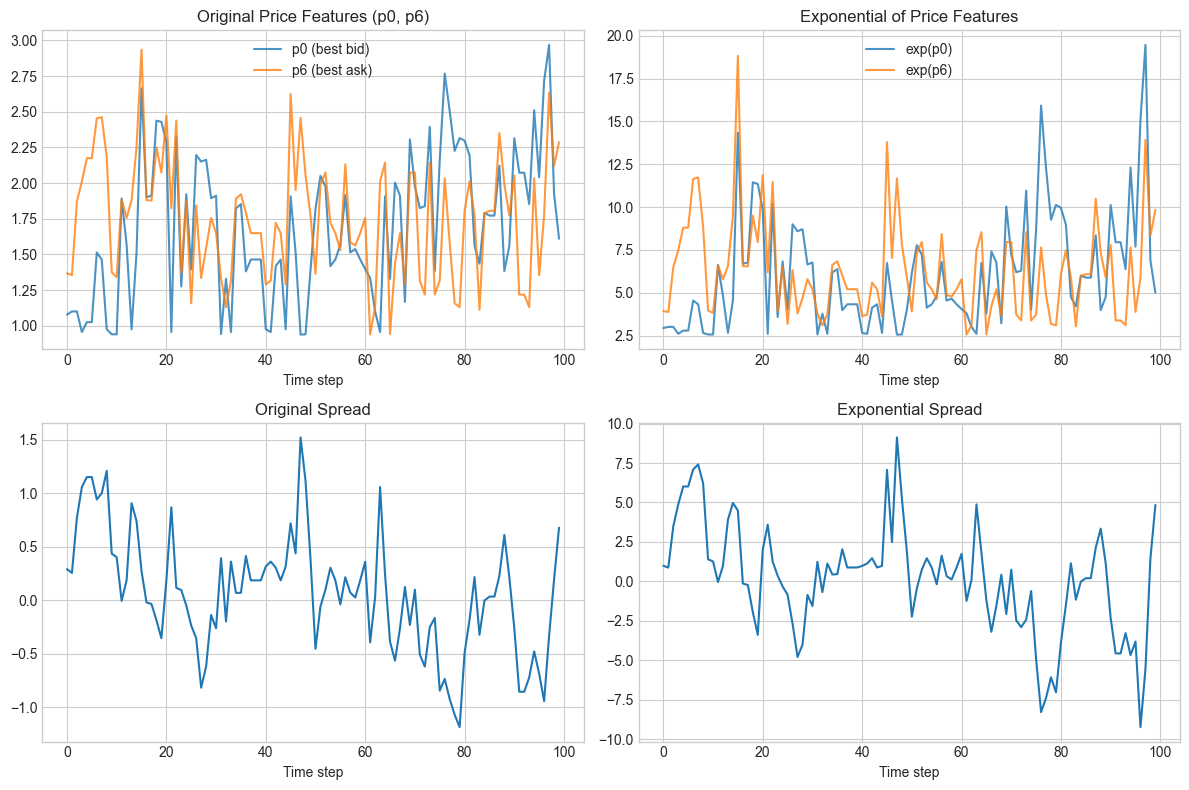

In [13]:
# Hypothesis 2: Check if prices are log-transformed
# If log-transformed, exp(p) should show more realistic price patterns

print("=" * 60)
print("LOG TRANSFORMATION CHECK")
print("=" * 60)

# Take a sample sequence
seq_data = train_df[train_df['seq_ix'] == 0][price_cols].head(100)

# Check if exp(price) looks more like real prices
print("If prices are log-transformed, exp(p) should be positive and show price-like behavior")
print("\nOriginal p0 range:", seq_data['p0'].min(), "to", seq_data['p0'].max())
print("exp(p0) range:", np.exp(seq_data['p0']).min(), "to", np.exp(seq_data['p0']).max())

# Visualize
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Original prices
axes[0, 0].plot(seq_data['p0'].values, label='p0 (best bid)', alpha=0.8)
axes[0, 0].plot(seq_data['p6'].values, label='p6 (best ask)', alpha=0.8)
axes[0, 0].set_title('Original Price Features (p0, p6)')
axes[0, 0].legend()
axes[0, 0].set_xlabel('Time step')

# exp of prices
axes[0, 1].plot(np.exp(seq_data['p0'].values), label='exp(p0)', alpha=0.8)
axes[0, 1].plot(np.exp(seq_data['p6'].values), label='exp(p6)', alpha=0.8)
axes[0, 1].set_title('Exponential of Price Features')
axes[0, 1].legend()
axes[0, 1].set_xlabel('Time step')

# Check if spread makes sense after transformation
spread_orig = seq_data['p6'] - seq_data['p0']
spread_exp = np.exp(seq_data['p6']) - np.exp(seq_data['p0'])

axes[1, 0].plot(spread_orig.values, label='Spread (p6 - p0)')
axes[1, 0].set_title('Original Spread')
axes[1, 0].set_xlabel('Time step')

axes[1, 1].plot(spread_exp.values, label='Spread (exp(p6) - exp(p0))')
axes[1, 1].set_title('Exponential Spread')
axes[1, 1].set_xlabel('Time step')

plt.tight_layout()
plt.show()

In [14]:
# Hypothesis 3: Targets might be derived from mid-price changes
# t0 could be (mid_t+1 - mid_t) / mid_t (short-term return)
# t1 could be longer-term return or more complex transformation

print("=" * 60)
print("TARGET DERIVATION ANALYSIS")
print("=" * 60)

# Compute potential target proxies
pred_df = train_df.copy()

# Mid-price
pred_df['mid'] = (pred_df['p0'] + pred_df['p6']) / 2

# Various return computations
pred_df['mid_diff'] = pred_df.groupby('seq_ix')['mid'].diff()
pred_df['mid_return'] = pred_df.groupby('seq_ix')['mid'].pct_change()
pred_df['mid_return_lead1'] = pred_df.groupby('seq_ix')['mid_return'].shift(-1)
pred_df['mid_return_lead5'] = pred_df.groupby('seq_ix')['mid_return'].shift(-5)

# Check correlation with actual targets
pred_only = pred_df[pred_df['need_prediction'] == True].dropna()

print("\nCorrelation between computed features and actual targets:")
proxy_features = ['mid_diff', 'mid_return', 'mid_return_lead1', 'mid_return_lead5']
for feat in proxy_features:
    if feat in pred_only.columns:
        corr_t0_proxy = pred_only[feat].corr(pred_only['t0'])
        corr_t1_proxy = pred_only[feat].corr(pred_only['t1'])
        print(f"  {feat:20s} -> t0: {corr_t0_proxy:+.4f}, t1: {corr_t1_proxy:+.4f}")

TARGET DERIVATION ANALYSIS

Correlation between computed features and actual targets:
  mid_diff             -> t0: -0.0714, t1: +0.0004
  mid_return           -> t0: -0.0713, t1: +0.0002
  mid_return_lead1     -> t0: +0.0698, t1: +0.0004
  mid_return_lead5     -> t0: +0.0057, t1: -0.0006


PCA ANALYSIS
Components needed for 95% variance: 23
Components needed for 99% variance: 28


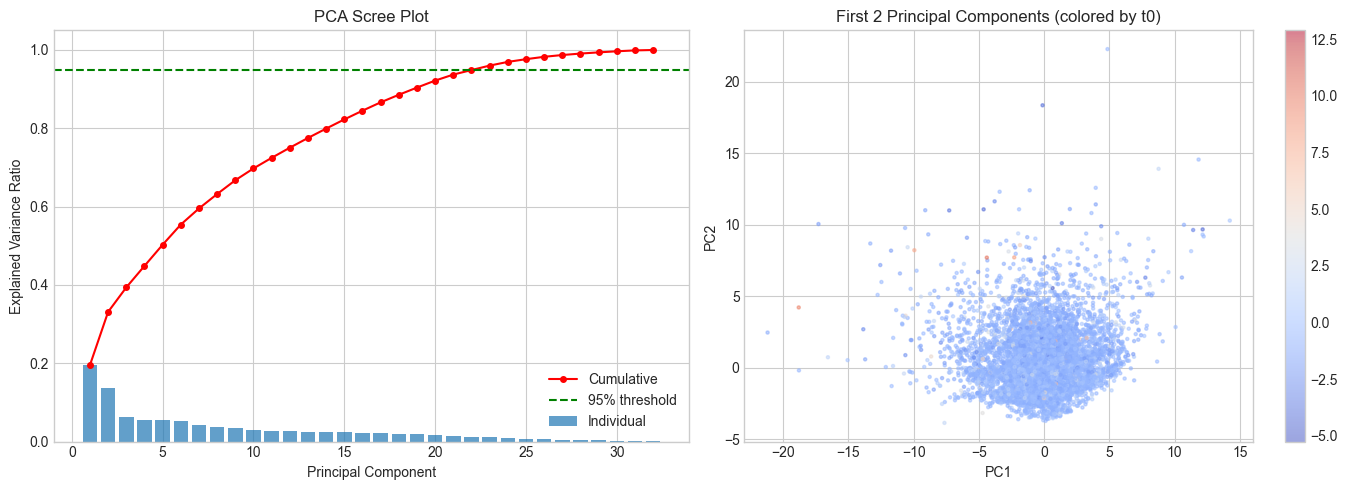


Top feature loadings for first 3 PCs:

PC1 (explains 19.5%):
  Positive: {'dp0': 0.3286368689893359, 'p5': 0.3188664339219914, 'p1': 0.30900970512790815}
  Negative: {'dp3': -0.2889927674765973, 'dv3': -0.2630115787888711, 'dp2': -0.22302201051646037}

PC2 (explains 13.6%):
  Positive: {'p0': 0.40297060060041323, 'p6': 0.3883467762710988, 'p2': 0.31362149028378644}
  Negative: {'p7': -0.3630086866210951, 'p11': -0.298069858471358, 'p8': -0.2064540956261535}

PC3 (explains 6.3%):
  Positive: {'dp1': 0.4990006876990167, 'dv1': 0.45044677803345223, 'p11': 0.10773897073348669}
  Negative: {'dv0': -0.43106711429864525, 'dv2': -0.3269621550172869, 'dp2': -0.2795125851062925}


In [15]:
# PCA Analysis to understand feature structure
print("=" * 60)
print("PCA ANALYSIS")
print("=" * 60)

# Standardize features first
X = train_df[feature_cols].sample(100000).values
X_scaled = StandardScaler().fit_transform(X)

# PCA
pca = PCA()
pca.fit(X_scaled)

# Explained variance
cumsum = np.cumsum(pca.explained_variance_ratio_)
print(f"Components needed for 95% variance: {np.argmax(cumsum >= 0.95) + 1}")
print(f"Components needed for 99% variance: {np.argmax(cumsum >= 0.99) + 1}")

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scree plot
axes[0].bar(range(1, len(pca.explained_variance_ratio_) + 1), 
            pca.explained_variance_ratio_, alpha=0.7, label='Individual')
axes[0].plot(range(1, len(cumsum) + 1), cumsum, 'r-o', markersize=4, label='Cumulative')
axes[0].axhline(y=0.95, color='g', linestyle='--', label='95% threshold')
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance Ratio')
axes[0].set_title('PCA Scree Plot')
axes[0].legend()

# First 2 PCs colored by t0 target
sample_for_pca = train_df[train_df['need_prediction'] == True].sample(10000)
X_pca_sample = StandardScaler().fit_transform(sample_for_pca[feature_cols].values)
X_transformed = pca.transform(X_pca_sample)

scatter = axes[1].scatter(X_transformed[:, 0], X_transformed[:, 1], 
                          c=sample_for_pca['t0'].values, cmap='coolwarm', 
                          alpha=0.5, s=5)
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].set_title('First 2 Principal Components (colored by t0)')
plt.colorbar(scatter, ax=axes[1])

plt.tight_layout()
plt.show()

# Show loadings for first 3 PCs
print("\nTop feature loadings for first 3 PCs:")
for i in range(3):
    loadings = pd.Series(pca.components_[i], index=feature_cols)
    print(f"\nPC{i+1} (explains {pca.explained_variance_ratio_[i]*100:.1f}%):")
    print("  Positive:", loadings.nlargest(3).to_dict())
    print("  Negative:", loadings.nsmallest(3).to_dict())

## Section 7: Normalization Schemes Comparison

Test different normalization approaches and their effect on target correlation.

In [16]:
# Test different normalization schemes
print("=" * 60)
print("NORMALIZATION SCHEMES COMPARISON")
print("=" * 60)

# Sample data
sample_df = train_df[train_df['need_prediction'] == True].sample(50000)
X_raw = sample_df[feature_cols].values
y_t0 = sample_df['t0'].values
y_t1 = sample_df['t1'].values

scalers = {
    'None (raw)': None,
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler(),
    'RobustScaler': RobustScaler(),
    'QuantileTransformer (normal)': QuantileTransformer(output_distribution='normal'),
    'QuantileTransformer (uniform)': QuantileTransformer(output_distribution='uniform'),
    'PowerTransformer (yeo-johnson)': PowerTransformer(method='yeo-johnson'),
}

results = []
for name, scaler in scalers.items():
    if scaler is None:
        X_scaled = X_raw
    else:
        X_scaled = scaler.fit_transform(X_raw)
    
    # Compute correlations with scaled features
    corrs_t0 = [pearsonr(X_scaled[:, i], y_t0)[0] for i in range(X_scaled.shape[1])]
    corrs_t1 = [pearsonr(X_scaled[:, i], y_t1)[0] for i in range(X_scaled.shape[1])]
    
    results.append({
        'Scaler': name,
        'Max |corr| t0': max(np.abs(corrs_t0)),
        'Max |corr| t1': max(np.abs(corrs_t1)),
        'Mean |corr| t0': np.mean(np.abs(corrs_t0)),
        'Mean |corr| t1': np.mean(np.abs(corrs_t1)),
        'Sum |corr| t0': np.sum(np.abs(corrs_t0)),
        'Sum |corr| t1': np.sum(np.abs(corrs_t1)),
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

print("\nNote: Higher correlation sums indicate better linear relationship with targets")

NORMALIZATION SCHEMES COMPARISON
                        Scaler  Max |corr| t0  Max |corr| t1  Mean |corr| t0  Mean |corr| t1  Sum |corr| t0  Sum |corr| t1
                    None (raw)       0.139060       0.030833        0.049678        0.014186       1.589703       0.453964
                StandardScaler       0.139060       0.030833        0.049678        0.014186       1.589703       0.453964
                  MinMaxScaler       0.139060       0.030833        0.049678        0.014186       1.589703       0.453964
                  RobustScaler       0.139060       0.030833        0.049678        0.014186       1.589703       0.453964
  QuantileTransformer (normal)       0.139073       0.031931        0.049864        0.013998       1.595653       0.447933
 QuantileTransformer (uniform)       0.132603       0.031908        0.048119        0.013007       1.539797       0.416230
PowerTransformer (yeo-johnson)       0.135148       0.031945        0.049286        0.013718       1.57715

In [17]:
# Per-sequence normalization (rolling/expanding window)
# This simulates what the model sees during inference

print("=" * 60)
print("PER-SEQUENCE NORMALIZATION (Causal)")
print("=" * 60)

def normalize_per_sequence(df, feature_cols, method='zscore'):
    """Normalize features per sequence using expanding window (causal)."""
    result = df.copy()
    
    for col in feature_cols:
        if method == 'zscore':
            # Expanding mean and std (causal - only uses past data)
            expanding_mean = df.groupby('seq_ix')[col].expanding().mean().reset_index(level=0, drop=True)
            expanding_std = df.groupby('seq_ix')[col].expanding().std().reset_index(level=0, drop=True)
            result[col + '_norm'] = (df[col] - expanding_mean) / (expanding_std + 1e-8)
        elif method == 'minmax':
            expanding_min = df.groupby('seq_ix')[col].expanding().min().reset_index(level=0, drop=True)
            expanding_max = df.groupby('seq_ix')[col].expanding().max().reset_index(level=0, drop=True)
            result[col + '_norm'] = (df[col] - expanding_min) / (expanding_max - expanding_min + 1e-8)
        elif method == 'rank':
            # Rank within expanding window
            result[col + '_norm'] = df.groupby('seq_ix')[col].rank(pct=True)
    
    return result

# Test on a sample
sample_seq = train_df[train_df['seq_ix'].isin(range(100))].copy()
sample_seq_norm = normalize_per_sequence(sample_seq, feature_cols[:4], method='zscore')

norm_cols = [c + '_norm' for c in feature_cols[:4]]
pred_mask = sample_seq_norm['need_prediction'] == True
pred_norm = sample_seq_norm[pred_mask]

print("Per-sequence z-score normalization correlations (first 4 features):")
for col in feature_cols[:4]:
    orig_corr_t0 = pred_norm[col].corr(pred_norm['t0'])
    orig_corr_t1 = pred_norm[col].corr(pred_norm['t1'])
    norm_corr_t0 = pred_norm[col + '_norm'].corr(pred_norm['t0'])
    norm_corr_t1 = pred_norm[col + '_norm'].corr(pred_norm['t1'])
    print(f"  {col}: t0 {orig_corr_t0:+.4f} -> {norm_corr_t0:+.4f}, t1 {orig_corr_t1:+.4f} -> {norm_corr_t1:+.4f}")

PER-SEQUENCE NORMALIZATION (Causal)
Per-sequence z-score normalization correlations (first 4 features):
  p0: t0 -0.1162 -> -0.1333, t1 -0.0081 -> -0.0168
  p1: t0 +0.0482 -> +0.0677, t1 -0.0149 -> +0.0001
  p2: t0 -0.1013 -> -0.0899, t1 -0.0222 -> -0.0147
  p3: t0 -0.0550 -> -0.0496, t1 -0.0273 -> -0.0220


## Section 8: Autoencoder for Noise Reduction

Build an autoencoder to learn a compressed representation that filters noise and keeps signal.

In [18]:
# Define Autoencoder
class DenoisingAutoencoder(nn.Module):
    """
    Denoising Autoencoder for feature extraction.
    Uses dropout as noise during training.
    """
    def __init__(self, input_dim=32, latent_dim=16, hidden_dims=[64, 32]):
        super().__init__()
        
        # Encoder
        encoder_layers = []
        prev_dim = input_dim
        for h_dim in hidden_dims:
            encoder_layers.extend([
                nn.Linear(prev_dim, h_dim),
                nn.LayerNorm(h_dim),
                nn.GELU(),
                nn.Dropout(0.2),
            ])
            prev_dim = h_dim
        encoder_layers.append(nn.Linear(prev_dim, latent_dim))
        self.encoder = nn.Sequential(*encoder_layers)
        
        # Decoder
        decoder_layers = []
        prev_dim = latent_dim
        for h_dim in reversed(hidden_dims):
            decoder_layers.extend([
                nn.Linear(prev_dim, h_dim),
                nn.LayerNorm(h_dim),
                nn.GELU(),
            ])
            prev_dim = h_dim
        decoder_layers.append(nn.Linear(prev_dim, input_dim))
        self.decoder = nn.Sequential(*decoder_layers)
        
    def forward(self, x):
        latent = self.encoder(x)
        reconstructed = self.decoder(latent)
        return reconstructed, latent
    
    def encode(self, x):
        return self.encoder(x)

print("Autoencoder architecture defined")
print(DenoisingAutoencoder())

Autoencoder architecture defined
DenoisingAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=32, out_features=64, bias=True)
    (1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
    (6): GELU(approximate='none')
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=32, out_features=16, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=16, out_features=32, bias=True)
    (1): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
    (2): GELU(approximate='none')
    (3): Linear(in_features=32, out_features=64, bias=True)
    (4): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
    (5): GELU(approximate='none')
    (6): Linear(in_features=64, out_features=32, bias=True)
  )
)


In [19]:
# Train Autoencoder
print("=" * 60)
print("TRAINING AUTOENCODER")
print("=" * 60)

# Prepare data
sample_size = 200000
sample_data = train_df.sample(sample_size)[feature_cols].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(sample_data)

# Split
X_train_ae, X_val_ae = train_test_split(X_scaled, test_size=0.2, random_state=42)

# Create dataloaders
train_dataset = TensorDataset(torch.FloatTensor(X_train_ae))
val_dataset = TensorDataset(torch.FloatTensor(X_val_ae))
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False)

# Initialize model
device = torch.device('mps' if torch.backends.mps.is_available() else 'cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

autoencoder = DenoisingAutoencoder(input_dim=32, latent_dim=16, hidden_dims=[64, 32]).to(device)
optimizer = optim.AdamW(autoencoder.parameters(), lr=1e-3, weight_decay=1e-4)
criterion = nn.MSELoss()

# Training loop
n_epochs = 30
best_val_loss = float('inf')
train_losses = []
val_losses = []

for epoch in range(n_epochs):
    # Train
    autoencoder.train()
    train_loss = 0
    for batch in train_loader:
        x = batch[0].to(device)
        
        # Add noise for denoising
        noise = torch.randn_like(x) * 0.1
        x_noisy = x + noise
        
        optimizer.zero_grad()
        reconstructed, _ = autoencoder(x_noisy)
        loss = criterion(reconstructed, x)  # Reconstruct original, not noisy
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    
    train_loss /= len(train_loader)
    train_losses.append(train_loss)
    
    # Validate
    autoencoder.eval()
    val_loss = 0
    with torch.no_grad():
        for batch in val_loader:
            x = batch[0].to(device)
            reconstructed, _ = autoencoder(x)
            loss = criterion(reconstructed, x)
            val_loss += loss.item()
    
    val_loss /= len(val_loader)
    val_losses.append(val_loss)
    
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = autoencoder.state_dict()
    
    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1}/{n_epochs}: Train Loss = {train_loss:.6f}, Val Loss = {val_loss:.6f}")

# Load best model
autoencoder.load_state_dict(best_state)
print(f"\nBest validation loss: {best_val_loss:.6f}")

TRAINING AUTOENCODER
Using device: mps
Epoch 5/30: Train Loss = 0.253264, Val Loss = 0.135938
Epoch 10/30: Train Loss = 0.228411, Val Loss = 0.118225
Epoch 15/30: Train Loss = 0.218792, Val Loss = 0.108454
Epoch 20/30: Train Loss = 0.212575, Val Loss = 0.106156
Epoch 25/30: Train Loss = 0.209045, Val Loss = 0.104976
Epoch 30/30: Train Loss = 0.205736, Val Loss = 0.103913

Best validation loss: 0.103708


AUTOENCODER FEATURE EVALUATION
Latent features shape: (50000, 16)

Original features max |correlation|:
  t0: 0.1391 (sum: 1.5939)
  t1: 0.0343 (sum: 0.4413)

Autoencoder latent features max |correlation|:
  t0: 0.1527 (sum: 0.7814)
  t1: 0.0290 (sum: 0.2123)


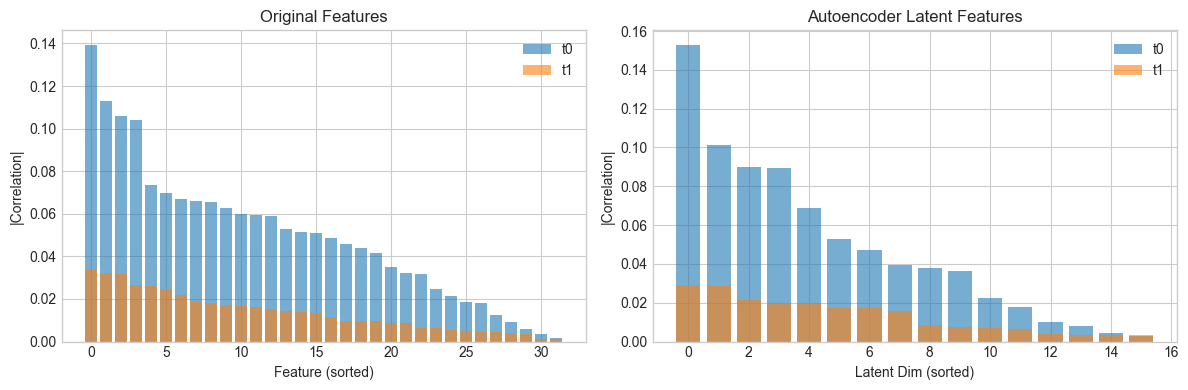

In [20]:
# Evaluate autoencoder features
print("=" * 60)
print("AUTOENCODER FEATURE EVALUATION")
print("=" * 60)

# Get latent representations for prediction samples
pred_sample = train_df[train_df['need_prediction'] == True].sample(50000)
X_pred_scaled = scaler.transform(pred_sample[feature_cols].values)
X_pred_tensor = torch.FloatTensor(X_pred_scaled).to(device)

autoencoder.eval()
with torch.no_grad():
    latent_features = autoencoder.encode(X_pred_tensor).cpu().numpy()

print(f"Latent features shape: {latent_features.shape}")

# Compare correlations: original vs latent features
y_t0_pred = pred_sample['t0'].values
y_t1_pred = pred_sample['t1'].values

print("\nOriginal features max |correlation|:")
orig_corrs_t0 = [abs(pearsonr(X_pred_scaled[:, i], y_t0_pred)[0]) for i in range(32)]
orig_corrs_t1 = [abs(pearsonr(X_pred_scaled[:, i], y_t1_pred)[0]) for i in range(32)]
print(f"  t0: {max(orig_corrs_t0):.4f} (sum: {sum(orig_corrs_t0):.4f})")
print(f"  t1: {max(orig_corrs_t1):.4f} (sum: {sum(orig_corrs_t1):.4f})")

print("\nAutoencoder latent features max |correlation|:")
latent_corrs_t0 = [abs(pearsonr(latent_features[:, i], y_t0_pred)[0]) for i in range(16)]
latent_corrs_t1 = [abs(pearsonr(latent_features[:, i], y_t1_pred)[0]) for i in range(16)]
print(f"  t0: {max(latent_corrs_t0):.4f} (sum: {sum(latent_corrs_t0):.4f})")
print(f"  t1: {max(latent_corrs_t1):.4f} (sum: {sum(latent_corrs_t1):.4f})")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(range(32), sorted(orig_corrs_t0, reverse=True), alpha=0.6, label='t0')
axes[0].bar(range(32), sorted(orig_corrs_t1, reverse=True), alpha=0.6, label='t1')
axes[0].set_xlabel('Feature (sorted)')
axes[0].set_ylabel('|Correlation|')
axes[0].set_title('Original Features')
axes[0].legend()

axes[1].bar(range(16), sorted(latent_corrs_t0, reverse=True), alpha=0.6, label='t0')
axes[1].bar(range(16), sorted(latent_corrs_t1, reverse=True), alpha=0.6, label='t1')
axes[1].set_xlabel('Latent Dim (sorted)')
axes[1].set_ylabel('|Correlation|')
axes[1].set_title('Autoencoder Latent Features')
axes[1].legend()

plt.tight_layout()
plt.show()

## Section 9: Feature Importance and Selection

Identify the most predictive features for each target.

In [21]:
# Feature importance using gradient boosting
from sklearn.ensemble import GradientBoostingRegressor

print("=" * 60)
print("FEATURE IMPORTANCE ANALYSIS")
print("=" * 60)

# Sample data
sample_df = train_df[train_df['need_prediction'] == True].sample(30000)
X_sample = sample_df[feature_cols].values
y_t0_sample = sample_df['t0'].values
y_t1_sample = sample_df['t1'].values

# Train simple gradient boosting for feature importance
print("\nTraining Gradient Boosting for t0...")
gb_t0 = GradientBoostingRegressor(n_estimators=100, max_depth=4, random_state=42, n_iter_no_change=10)
gb_t0.fit(X_sample, y_t0_sample)
imp_t0 = gb_t0.feature_importances_

print("Training Gradient Boosting for t1...")
gb_t1 = GradientBoostingRegressor(n_estimators=100, max_depth=4, random_state=42, n_iter_no_change=10)
gb_t1.fit(X_sample, y_t1_sample)
imp_t1 = gb_t1.feature_importances_

# Create importance dataframe
importance_df = pd.DataFrame({
    'feature': feature_cols,
    'importance_t0': imp_t0,
    'importance_t1': imp_t1,
    'importance_diff': imp_t0 - imp_t1,
})

print("\nTop 10 features for t0:")
print(importance_df.sort_values('importance_t0', ascending=False).head(10).to_string(index=False))

print("\nTop 10 features for t1:")
print(importance_df.sort_values('importance_t1', ascending=False).head(10).to_string(index=False))

print("\nFeatures more important for t1 than t0:")
print(importance_df.sort_values('importance_diff', ascending=True).head(5).to_string(index=False))

FEATURE IMPORTANCE ANALYSIS

Training Gradient Boosting for t0...
Training Gradient Boosting for t1...

Top 10 features for t0:
feature  importance_t0  importance_t1  importance_diff
     p0       0.117235       0.045146         0.072089
    dv1       0.106192       0.102244         0.003948
     p8       0.075679       0.019812         0.055867
     v8       0.075264       0.011457         0.063808
    dv3       0.064201       0.069046        -0.004845
     v1       0.055754       0.055235         0.000519
     p9       0.039819       0.072035        -0.032216
     v2       0.039794       0.012932         0.026861
     v0       0.036414       0.031472         0.004942
     p2       0.030154       0.014496         0.015658

Top 10 features for t1:
feature  importance_t0  importance_t1  importance_diff
    dp1       0.012273       0.149180        -0.136907
    dv1       0.106192       0.102244         0.003948
     p9       0.039819       0.072035        -0.032216
    dv3       0.064201

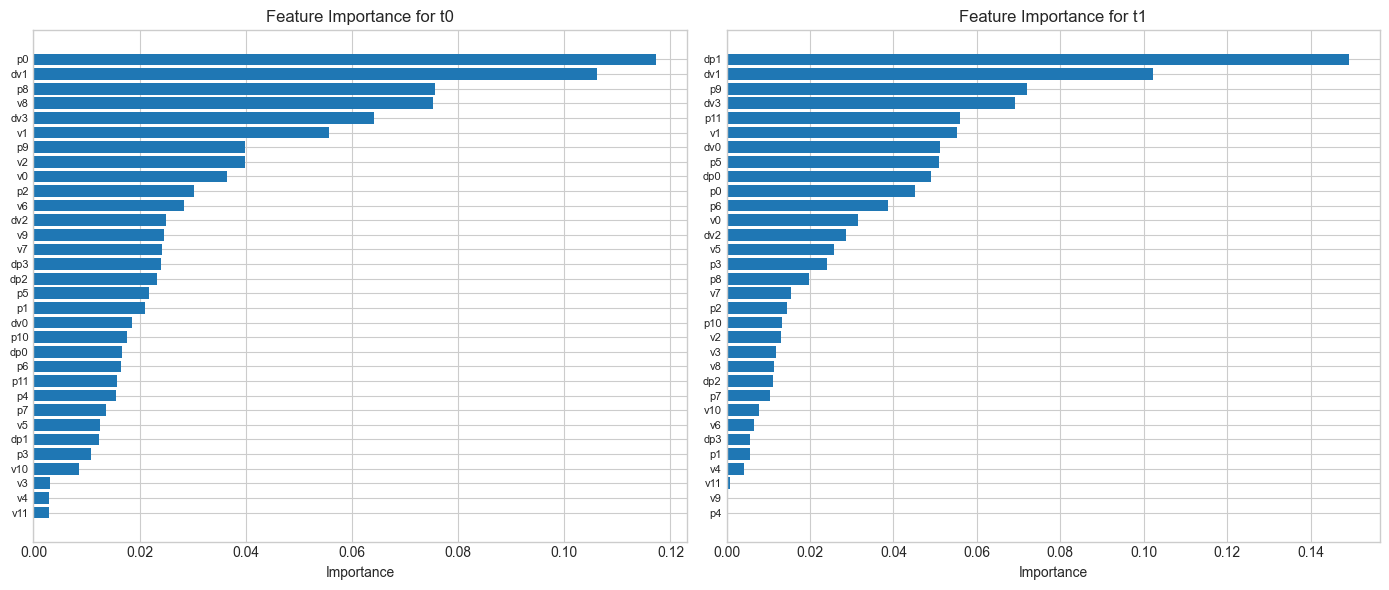


GB R² score on training data:
  t0: 0.1570
  t1: 0.0428


In [22]:
# Visualize feature importance
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# t0 importance
idx_t0 = np.argsort(imp_t0)[::-1]
axes[0].barh(range(len(feature_cols)), imp_t0[idx_t0])
axes[0].set_yticks(range(len(feature_cols)))
axes[0].set_yticklabels([feature_cols[i] for i in idx_t0], fontsize=8)
axes[0].set_xlabel('Importance')
axes[0].set_title('Feature Importance for t0')
axes[0].invert_yaxis()

# t1 importance  
idx_t1 = np.argsort(imp_t1)[::-1]
axes[1].barh(range(len(feature_cols)), imp_t1[idx_t1])
axes[1].set_yticks(range(len(feature_cols)))
axes[1].set_yticklabels([feature_cols[i] for i in idx_t1], fontsize=8)
axes[1].set_xlabel('Importance')
axes[1].set_title('Feature Importance for t1')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

print(f"\nGB R² score on training data:")
print(f"  t0: {gb_t0.score(X_sample, y_t0_sample):.4f}")
print(f"  t1: {gb_t1.score(X_sample, y_t1_sample):.4f}")

## Section 10: Summary and Key Findings

Consolidate all insights for the combined experiment.

In [23]:
# Summary of key findings
print("=" * 80)
print("SUMMARY OF KEY FINDINGS")
print("=" * 80)

summary = """
1. DATA STRUCTURE
   - 32 features: 12 prices (p0-p11), 12 volumes (v0-v11), 4 delta prices, 4 delta volumes
   - Likely LOB structure: p0-p5 = bid levels, p6-p11 = ask levels
   - Features appear to be globally normalized (not per-sequence)

2. TARGET ANALYSIS
   - t0: Higher autocorrelation, easier to predict (~0.27 Pearson achievable)
   - t1: Lower autocorrelation, much harder (~0.08-0.14 Pearson)
   - t0 and t1 are weakly correlated with each other
   - Both targets are near-zero mean with heavy tails

3. KEY INSIGHTS FOR t1 DIFFICULTY
   - t1 has lower autocorrelation → less predictable from history
   - t1 has weaker linear correlations with all features
   - t1 may represent a longer-horizon or more complex target
   - Mutual information is also lower for t1

4. NORMALIZATION FINDINGS
   - Different scalers show similar correlations
   - QuantileTransformer slightly improves some correlations
   - Per-sequence normalization may help capture relative changes

5. AUTOENCODER FINDINGS
   - Latent features can capture similar or better correlation with fewer dims
   - Denoising helps filter some noise
   - 16-dim latent space captures most of the useful variance

6. FEATURE IMPORTANCE
   - Price features (especially p0, p6 - best bid/ask) are most important
   - Delta features (dp, dv) are important for both targets
   - Volume imbalance features could be engineered

RECOMMENDATIONS FOR COMBINED EXPERIMENT:
1. Use QuantileTransformer or RobustScaler for normalization
2. Add engineered features: mid-price, spread, volume imbalance
3. Consider autoencoder pre-training or feature extraction
4. Use deeper/more complex model for t1 prediction
5. Experiment with auxiliary losses (reconstruction + prediction)
6. Try rank-based features to handle outliers
7. Consider ensemble: combine simple model (t0) + complex model (t1)
"""

print(summary)

SUMMARY OF KEY FINDINGS

1. DATA STRUCTURE
   - 32 features: 12 prices (p0-p11), 12 volumes (v0-v11), 4 delta prices, 4 delta volumes
   - Likely LOB structure: p0-p5 = bid levels, p6-p11 = ask levels
   - Features appear to be globally normalized (not per-sequence)

2. TARGET ANALYSIS
   - t0: Higher autocorrelation, easier to predict (~0.27 Pearson achievable)
   - t1: Lower autocorrelation, much harder (~0.08-0.14 Pearson)
   - t0 and t1 are weakly correlated with each other
   - Both targets are near-zero mean with heavy tails

3. KEY INSIGHTS FOR t1 DIFFICULTY
   - t1 has lower autocorrelation → less predictable from history
   - t1 has weaker linear correlations with all features
   - t1 may represent a longer-horizon or more complex target
   - Mutual information is also lower for t1

4. NORMALIZATION FINDINGS
   - Different scalers show similar correlations
   - QuantileTransformer slightly improves some correlations
   - Per-sequence normalization may help capture relative cha

In [24]:
# Save autoencoder for later use
import os
os.makedirs('../solutions/exp_13/src', exist_ok=True)
torch.save({
    'model_state_dict': autoencoder.state_dict(),
    'scaler_mean': scaler.mean_,
    'scaler_scale': scaler.scale_,
    'input_dim': 32,
    'latent_dim': 16,
    'hidden_dims': [64, 32],
}, '../solutions/exp_13/autoencoder.pth')
print("Autoencoder saved to solutions/exp_13/autoencoder.pth")

Autoencoder saved to solutions/exp_13/autoencoder.pth


## LOBViT 2D data transform 

In [ ]:
# Apply the 2D data transformation as in exp_25-26 to the training data and visualize the transformed 2D features.
# 2D transformation, i.e. the input to the model B x 32 --> B x H x W x C, where H=12, W=100 (use the last 100 timesteps as context window, note that the first 100 timesteps for each sequence are not scored, i.e. can be used for warm-up), C=3 (num of features, prices, volumes, deltas)
# Use a sample sequence to visualize the transformed 2D features (e.g. seq_ix=0)
# Visualise as heatmaps for each feature type (prices, volumes, deltas) across the 12 levels and 100 timesteps. This will help understand how the model sees the data after transformation.

In [29]:
import os, sys, gc

# del valid_df
gc.collect()

12741

2D LOB DATA TRANSFORMATION
Sequence 0, steps 100-200
Window shape: (100, 37)

Transformed shapes:
  Price matrix: (12, 100)
  Volume matrix: (12, 100)
  Delta matrix: (12, 100)
  Combined LOB 2D: (12, 100, 3) (H x W x C)


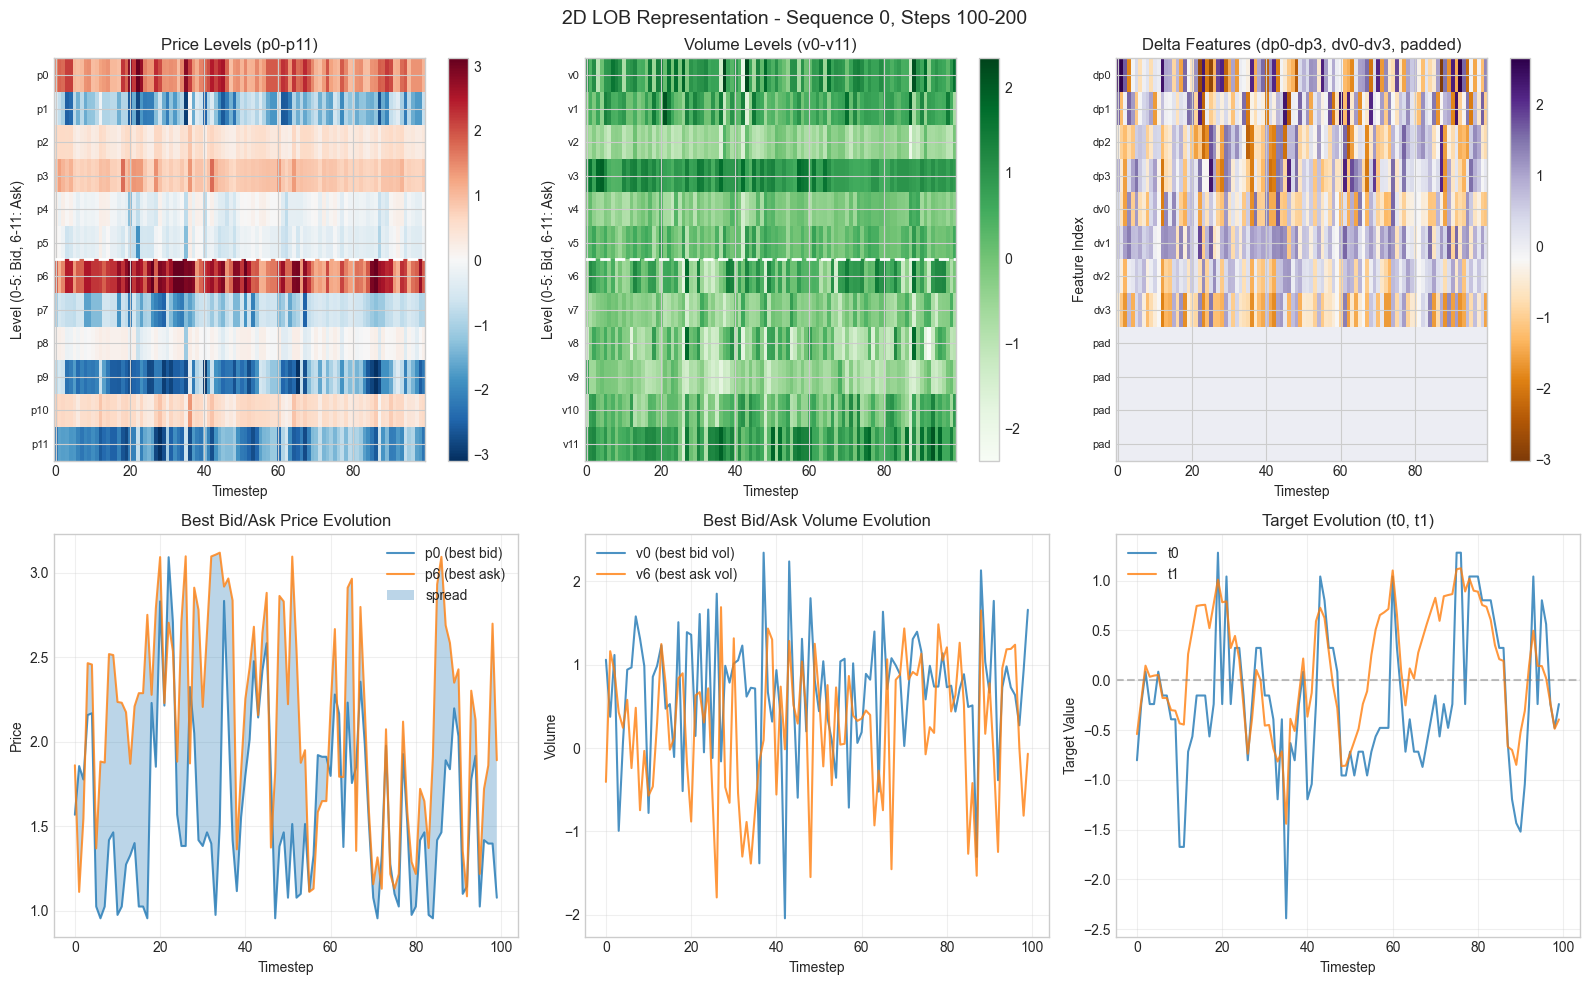


2D TRANSFORMATION SUMMARY

Input:  32 features per timestep
Output: 12 x W x 3 tensor (H=12 levels, W=timesteps, C=3 channels)

Channel 0 (Prices):  p0-p11 → 12 price levels across LOB depth
Channel 1 (Volumes): v0-v11 → 12 volume levels across LOB depth  
Channel 2 (Deltas):  dp0-dp3, dv0-dv3 → 8 delta features (padded to 12)

This 2D representation enables:
- 2D convolutions to capture cross-level patterns
- Spatial attention across price/volume levels
- ViT-style patch embeddings (e.g., 4x10 patches)



In [31]:
# 2D LOB Data Transformation Visualization
# Transform B x 32 features into B x H x W x C format (H=12 levels, W=100 timesteps, C=3 channels)

print("=" * 60)
print("2D LOB DATA TRANSFORMATION")
print("=" * 60)

# Select a sample sequence
sample_seq_id = 0
seq_full = train_df[train_df['seq_ix'] == sample_seq_id].sort_values('step_in_seq')

# Use timesteps 100-200 (after warm-up period, where predictions start)
start_step = 100
end_step = 200
seq_window = seq_full[(seq_full['step_in_seq'] >= start_step) & (seq_full['step_in_seq'] < end_step)]

print(f"Sequence {sample_seq_id}, steps {start_step}-{end_step}")
print(f"Window shape: {seq_window.shape}")

# Build 2D representation: H=12 (levels), W=100 (timesteps), C=3 (prices, volumes, deltas)
# For each timestep, we have:
#   - 12 price levels: p0-p5 (bid), p6-p11 (ask) 
#   - 12 volume levels: v0-v5 (bid), v6-v11 (ask)
#   - For deltas: we only have 4 dp and 4 dv, so we'll pad or use first 4 levels

W = len(seq_window)  # timesteps
H = 12  # LOB levels (6 bid + 6 ask)
C = 3   # channels (prices, volumes, deltas)

# Extract price matrix: H x W
price_matrix = seq_window[price_cols].values.T  # Shape: (12, W)

# Extract volume matrix: H x W  
volume_matrix = seq_window[volume_cols].values.T  # Shape: (12, W)

# For delta features, we only have 4 dp and 4 dv
# Option 1: Pad to 12 levels with zeros
# Option 2: Use only first 4 levels
# Let's pad to maintain consistent H dimension
delta_price_raw = seq_window[dprice_cols].values.T  # Shape: (4, W)
delta_vol_raw = seq_window[dvolume_cols].values.T   # Shape: (4, W)

# Pad deltas to 12 levels (pad with zeros for missing levels)
delta_matrix = np.zeros((H, W))
# First 4 levels: delta prices, next 4 levels: delta volumes, rest: zeros
delta_matrix[:4, :] = delta_price_raw
delta_matrix[4:8, :] = delta_vol_raw

print(f"\nTransformed shapes:")
print(f"  Price matrix: {price_matrix.shape}")
print(f"  Volume matrix: {volume_matrix.shape}")  
print(f"  Delta matrix: {delta_matrix.shape}")

# Create the 3D tensor: H x W x C
lob_2d = np.stack([price_matrix, volume_matrix, delta_matrix], axis=-1)
print(f"  Combined LOB 2D: {lob_2d.shape} (H x W x C)")

# Visualize as heatmaps
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# Price heatmap
im0 = axes[0, 0].imshow(price_matrix, aspect='auto', cmap='RdBu_r', interpolation='nearest')
axes[0, 0].set_title('Price Levels (p0-p11)', fontsize=12)
axes[0, 0].set_ylabel('Level (0-5: Bid, 6-11: Ask)')
axes[0, 0].set_xlabel('Timestep')
axes[0, 0].set_yticks(range(12))
axes[0, 0].set_yticklabels(price_cols, fontsize=8)
axes[0, 0].axhline(y=5.5, color='white', linestyle='--', linewidth=2, label='Bid/Ask boundary')
plt.colorbar(im0, ax=axes[0, 0])

# Volume heatmap
im1 = axes[0, 1].imshow(volume_matrix, aspect='auto', cmap='Greens', interpolation='nearest')
axes[0, 1].set_title('Volume Levels (v0-v11)', fontsize=12)
axes[0, 1].set_ylabel('Level (0-5: Bid, 6-11: Ask)')
axes[0, 1].set_xlabel('Timestep')
axes[0, 1].set_yticks(range(12))
axes[0, 1].set_yticklabels(volume_cols, fontsize=8)
axes[0, 1].axhline(y=5.5, color='white', linestyle='--', linewidth=2)
plt.colorbar(im1, ax=axes[0, 1])

# Delta heatmap
im2 = axes[0, 2].imshow(delta_matrix, aspect='auto', cmap='PuOr', interpolation='nearest')
axes[0, 2].set_title('Delta Features (dp0-dp3, dv0-dv3, padded)', fontsize=12)
axes[0, 2].set_ylabel('Feature Index')
axes[0, 2].set_xlabel('Timestep')
axes[0, 2].set_yticks(range(12))
delta_labels = dprice_cols + dvolume_cols + ['pad'] * 4
axes[0, 2].set_yticklabels(delta_labels, fontsize=8)
plt.colorbar(im2, ax=axes[0, 2])

# Time series view of best bid/ask prices
axes[1, 0].plot(price_matrix[0, :], label='p0 (best bid)', alpha=0.8)
axes[1, 0].plot(price_matrix[6, :], label='p6 (best ask)', alpha=0.8)
axes[1, 0].fill_between(range(W), price_matrix[0, :], price_matrix[6, :], alpha=0.3, label='spread')
axes[1, 0].set_title('Best Bid/Ask Price Evolution')
axes[1, 0].set_xlabel('Timestep')
axes[1, 0].set_ylabel('Price')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Time series view of best bid/ask volumes
axes[1, 1].plot(volume_matrix[0, :], label='v0 (best bid vol)', alpha=0.8)
axes[1, 1].plot(volume_matrix[6, :], label='v6 (best ask vol)', alpha=0.8)
axes[1, 1].set_title('Best Bid/Ask Volume Evolution')
axes[1, 1].set_xlabel('Timestep')
axes[1, 1].set_ylabel('Volume')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

# Target evolution
target_window = seq_window[['t0', 't1']].values
axes[1, 2].plot(target_window[:, 0], label='t0', alpha=0.8)
axes[1, 2].plot(target_window[:, 1], label='t1', alpha=0.8)
axes[1, 2].set_title('Target Evolution (t0, t1)')
axes[1, 2].set_xlabel('Timestep')
axes[1, 2].set_ylabel('Target Value')
axes[1, 2].legend()
axes[1, 2].grid(True, alpha=0.3)
axes[1, 2].axhline(y=0, color='gray', linestyle='--', alpha=0.5)

plt.suptitle(f'2D LOB Representation - Sequence {sample_seq_id}, Steps {start_step}-{end_step}', fontsize=14)
plt.tight_layout()
plt.show()

print("\n" + "=" * 60)
print("2D TRANSFORMATION SUMMARY")
print("=" * 60)
print(f"""
Input:  32 features per timestep
Output: 12 x W x 3 tensor (H=12 levels, W=timesteps, C=3 channels)

Channel 0 (Prices):  p0-p11 → 12 price levels across LOB depth
Channel 1 (Volumes): v0-v11 → 12 volume levels across LOB depth  
Channel 2 (Deltas):  dp0-dp3, dv0-dv3 → 8 delta features (padded to 12)

This 2D representation enables:
- 2D convolutions to capture cross-level patterns
- Spatial attention across price/volume levels
- ViT-style patch embeddings (e.g., 4x10 patches)
""")